<a href="https://colab.research.google.com/github/Aayush1509-PROG/Cognitive-Computing-Assignments/blob/main/Assignment%208.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Question 1

In [3]:
import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

# Download required NLTK resources
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)

# Paragraph about my favourite topic: Cricket
paragraph = """
Cricket is my favorite sport because it combines strategy, patience, and teamwork.
I enjoy watching international matches, especially when skilled batters build partnerships under pressure.
Fast bowlers use pace and swing, while spinners trick batters with flight and turn.
A great captain studies the pitch, chooses smart field placements, and motivates every player.
The final overs are exciting because one boundary can change the result.
Cricket teaches discipline, resilience, and respect for opponents.
"""

# 1. Convert to lowercase and remove punctuation
lower_text = paragraph.lower()
clean_text = re.sub(r'[^\w\s]', '', lower_text)

print("Original Paragraph:")
print(paragraph)

print("\nLowercase Text:")
print(lower_text)

print("\nText after removing punctuation:")
print(clean_text)

# 2. Tokenize into sentences and words
sentences = sent_tokenize(paragraph)
words = word_tokenize(clean_text)

print("\nSentence Tokens:")
print(sentences)

print("\nWord Tokens:")
print(words)

# 3. Compare split() and word_tokenize()
split_tokens = lower_text.split()
nltk_tokens = word_tokenize(lower_text)

print("\nTokens using split():")
print(split_tokens)

print("\nTokens using word_tokenize():")
print(nltk_tokens)

print("\nDifference:")
print("split() separates text mainly using whitespace.")
print("word_tokenize() recognizes punctuation as separate tokens.")

# 4. Remove stopwords
stop_words = set(stopwords.words('english'))

filtered_words = [
    word for word in words
    if word not in stop_words and word.isalpha()
]

print("\nWords after removing stopwords:")
print(filtered_words)

# 5. Display word frequency distribution
frequency = FreqDist(filtered_words)

print("\nWord Frequency Distribution:")
for word, count in frequency.most_common():
    print(f"{word}: {count}")

Original Paragraph:

Cricket is my favorite sport because it combines strategy, patience, and teamwork.
I enjoy watching international matches, especially when skilled batters build partnerships under pressure.
Fast bowlers use pace and swing, while spinners trick batters with flight and turn.
A great captain studies the pitch, chooses smart field placements, and motivates every player.
The final overs are exciting because one boundary can change the result.
Cricket teaches discipline, resilience, and respect for opponents.


Lowercase Text:

cricket is my favorite sport because it combines strategy, patience, and teamwork.
i enjoy watching international matches, especially when skilled batters build partnerships under pressure.
fast bowlers use pace and swing, while spinners trick batters with flight and turn.
a great captain studies the pitch, chooses smart field placements, and motivates every player.
the final overs are exciting because one boundary can change the result.
cricket t

Expected observation: split() generally leaves punctuation attached to words, whereas NLTK's tokenizer can separate punctuation into individual tokens. Stopword removal excludes common words such as the, and, and for. NLTK's word_tokenize() may require the downloaded sentence-tokenization resources.

Question 2

In [4]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

# Download required resources
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

# Same paragraph as Q1
paragraph = """
Cricket is my favorite sport because it combines strategy, patience, and teamwork.
I enjoy watching international matches, especially when skilled batters build partnerships under pressure.
Fast bowlers use pace and swing, while spinners trick batters with flight and turn.
A great captain studies the pitch, chooses smart field placements, and motivates every player.
The final overs are exciting because one boundary can change the result.
Cricket teaches discipline, resilience, and respect for opponents.
"""

# 1. Extract alphabetic words using regular expressions
words = re.findall(r'[a-zA-Z]+', paragraph.lower())

print("Alphabetic Words:")
print(words)

# 2. Remove stopwords
stop_words = set(stopwords.words('english'))

filtered_words = [
    word for word in words
    if word not in stop_words
]

print("\nWords after Removing Stopwords:")
print(filtered_words)

# 3. Perform stemming
stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(word) for word in filtered_words]

print("\nStemmed Words:")
print(stemmed_words)

# 4. Perform lemmatization
lemmatizer = WordNetLemmatizer()
lemmatized_words = [
    lemmatizer.lemmatize(word) for word in filtered_words
]

print("\nLemmatized Words:")
print(lemmatized_words)

# 5. Compare the outputs
print("\nComparison:")
for original, stem, lemma in zip(
    filtered_words, stemmed_words, lemmatized_words
):
    print(f"{original:15} Stem: {stem:12} Lemma: {lemma}")

Alphabetic Words:
['cricket', 'is', 'my', 'favorite', 'sport', 'because', 'it', 'combines', 'strategy', 'patience', 'and', 'teamwork', 'i', 'enjoy', 'watching', 'international', 'matches', 'especially', 'when', 'skilled', 'batters', 'build', 'partnerships', 'under', 'pressure', 'fast', 'bowlers', 'use', 'pace', 'and', 'swing', 'while', 'spinners', 'trick', 'batters', 'with', 'flight', 'and', 'turn', 'a', 'great', 'captain', 'studies', 'the', 'pitch', 'chooses', 'smart', 'field', 'placements', 'and', 'motivates', 'every', 'player', 'the', 'final', 'overs', 'are', 'exciting', 'because', 'one', 'boundary', 'can', 'change', 'the', 'result', 'cricket', 'teaches', 'discipline', 'resilience', 'and', 'respect', 'for', 'opponents']

Words after Removing Stopwords:
['cricket', 'favorite', 'sport', 'combines', 'strategy', 'patience', 'teamwork', 'enjoy', 'watching', 'international', 'matches', 'especially', 'skilled', 'batters', 'build', 'partnerships', 'pressure', 'fast', 'bowlers', 'use', 'pace

Explanations:
- Stemming: Removes word endings using rules. The result may not be a valid English word; for example, studies may become studi.
- Lemmatization: Converts a word to a dictionary form using linguistic information. For example, bowlers becomes bowler.
- Conclusion: Stemming is useful when faster, simpler text normalization is needed. Lemmatization is preferable when readable and linguistically meaningful words are important. WordNet lemmatization can also depend on the part of speech supplied to it.

Question 3

In [5]:
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# Three cricket-related texts
texts = [
    "The batter played attacking cricket. The batter scored a century and helped the cricket team win.",
    "The bowler used swing bowling. The bowler took five wickets with accurate yorkers in the final overs.",
    "The captain led the team calmly. The captain chose smart field placements and motivated the cricket team."
]

# 1. Bag of Words using CountVectorizer
count_vectorizer = CountVectorizer(stop_words='english')
bow_matrix = count_vectorizer.fit_transform(texts)

print("Bag of Words Vocabulary:")
print(count_vectorizer.get_feature_names_out())

print("\nBag of Words Matrix:")
print(bow_matrix.toarray())

# 2. Calculate TF-IDF scores
tfidf_vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

feature_names = tfidf_vectorizer.get_feature_names_out()

print("\nTF-IDF Matrix:")
print(np.round(tfidf_matrix.toarray(), 3))

# 3. Display top 3 keywords for each text
print("\nTop 3 Keywords for Each Text:")

for i, row in enumerate(tfidf_matrix.toarray()):
    # Sort by descending TF-IDF score
    top_indices = sorted(
        range(len(feature_names)),
        key=lambda j: (-row[j], feature_names[j])
    )[:3]

    print(f"\nText {i + 1}:")
    for index in top_indices:
        print(f"{feature_names[index]}: {row[index]:.4f}")

Bag of Words Vocabulary:
['accurate' 'attacking' 'batter' 'bowler' 'bowling' 'calmly' 'captain'
 'century' 'chose' 'cricket' 'field' 'final' 'helped' 'led' 'motivated'
 'overs' 'placements' 'played' 'scored' 'smart' 'swing' 'team' 'took'
 'used' 'wickets' 'win' 'yorkers']

Bag of Words Matrix:
[[0 1 2 0 0 0 0 1 0 2 0 0 1 0 0 0 0 1 1 0 0 1 0 0 0 1 0]
 [1 0 0 2 1 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 1 0 1 1 1 0 1]
 [0 0 0 0 0 1 2 0 1 1 1 0 0 1 1 0 1 0 0 1 0 2 0 0 0 0 0]]

TF-IDF Matrix:
[[0.    0.279 0.557 0.    0.    0.    0.    0.279 0.    0.424 0.    0.
  0.279 0.    0.    0.    0.    0.279 0.279 0.    0.    0.212 0.    0.
  0.    0.279 0.   ]
 [0.277 0.    0.    0.555 0.277 0.    0.    0.    0.    0.    0.    0.277
  0.    0.    0.    0.277 0.    0.    0.    0.    0.277 0.    0.277 0.277
  0.277 0.    0.277]
 [0.    0.    0.    0.    0.    0.268 0.537 0.    0.268 0.204 0.268 0.
  0.    0.268 0.268 0.    0.268 0.    0.    0.268 0.    0.408 0.    0.
  0.    0.    0.   ]]

Top 3 Keywords for E

Interpretation:

Bag of Words counts how often each vocabulary word occurs in each text. TF-IDF assigns higher importance to terms that are useful for distinguishing one document from the others, rather than simply counting occurrences. The top three keywords will be printed automatically. Because these are short texts, some terms may receive similar scores; the actual results depend on the vocabulary and all three documents.

Question 4

In [6]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Two technology descriptions, each with 5 lines
ai_text = """
Artificial intelligence enables computers to learn from data.
AI systems recognize patterns and solve complex problems.
Machine learning improves predictions through training.
AI is used in healthcare, education, and automation.
Intelligent systems help people make faster decisions.
"""

blockchain_text = """
Blockchain stores data across a distributed network.
Blocks record transactions in a linked digital ledger.
Cryptography helps keep blockchain records secure.
Blockchain supports digital payments and smart contracts.
Network participants verify transactions without one central authority.
"""

# 1. Preprocess and tokenize both texts
tokens_ai = re.findall(r'[a-zA-Z]+', ai_text.lower())
tokens_blockchain = re.findall(r'[a-zA-Z]+', blockchain_text.lower())

clean_ai = " ".join(tokens_ai)
clean_blockchain = " ".join(tokens_blockchain)

print("AI Tokens:")
print(tokens_ai)

print("\nBlockchain Tokens:")
print(tokens_blockchain)

# 2a. Jaccard Similarity using sets
set_ai = set(tokens_ai)
set_blockchain = set(tokens_blockchain)

intersection = set_ai.intersection(set_blockchain)
union = set_ai.union(set_blockchain)

jaccard = len(intersection) / len(union) if union else 0

print("\nCommon Words:")
print(intersection)

print("\nJaccard Similarity:", round(jaccard, 4))

# 2b. Cosine Similarity using TF-IDF
texts = [clean_ai, clean_blockchain]

vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform(texts)

cosine = cosine_similarity(
    tfidf_matrix[0:1],
    tfidf_matrix[1:2]
)[0][0]

print("Cosine Similarity:", round(cosine, 4))

# 2c. Compare the metrics
print("\nAnalysis:")
print("Jaccard measures the overlap between unique words.")
print("Cosine similarity compares TF-IDF-weighted text vectors.")

if jaccard < 0.2 and cosine < 0.2:
    print("Both metrics indicate low word-based similarity.")
else:
    print("The metrics show some degree of word-based similarity.")

print(
    "For these descriptions, cosine similarity can provide more "
    "information about term importance, while Jaccard gives a "
    "simple comparison of shared vocabulary."
)

AI Tokens:
['artificial', 'intelligence', 'enables', 'computers', 'to', 'learn', 'from', 'data', 'ai', 'systems', 'recognize', 'patterns', 'and', 'solve', 'complex', 'problems', 'machine', 'learning', 'improves', 'predictions', 'through', 'training', 'ai', 'is', 'used', 'in', 'healthcare', 'education', 'and', 'automation', 'intelligent', 'systems', 'help', 'people', 'make', 'faster', 'decisions']

Blockchain Tokens:
['blockchain', 'stores', 'data', 'across', 'a', 'distributed', 'network', 'blocks', 'record', 'transactions', 'in', 'a', 'linked', 'digital', 'ledger', 'cryptography', 'helps', 'keep', 'blockchain', 'records', 'secure', 'blockchain', 'supports', 'digital', 'payments', 'and', 'smart', 'contracts', 'network', 'participants', 'verify', 'transactions', 'without', 'one', 'central', 'authority']

Common Words:
{'data', 'in', 'and'}

Jaccard Similarity: 0.0492
Cosine Similarity: 0.048

Analysis:
Jaccard measures the overlap between unique words.
Cosine similarity compares TF-IDF-w

Analysis: Jaccard similarity considers the shared unique words divided by all unique words in both texts. Cosine similarity compares their TF-IDF vectors, accounting for term weighting. Cosine similarity is often more informative when term importance matters. However, neither metric truly understands meaning: AI and Blockchain could be conceptually related even when they use different vocabulary.

Question 5


Review 1: These headphones have excellent sound quality and deep bass. The battery lasts all day, and the fit is very comfortable.
Polarity: 0.362
Subjectivity: 0.617
Classification: Positive

Review 2: I love these headphones because they sound amazing. The delivery was fast, and the product is worth buying.
Polarity: 0.400
Subjectivity: 0.520
Classification: Positive

Review 3: The headphones feel cheap and the sound keeps cutting out. The battery life is poor, and customer support was unhelpful.
Polarity: -0.050
Subjectivity: 0.650
Classification: Neutral

Review 4: The headphones connect using Bluetooth and include a charging cable. They have adjustable ear cups and three control buttons.
Polarity: 0.000
Subjectivity: 0.000
Classification: Neutral


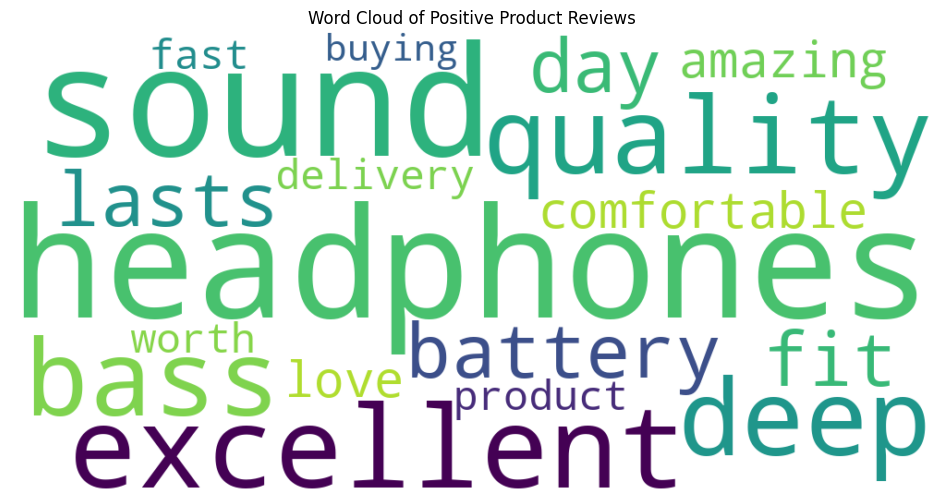

In [7]:
from textblob import TextBlob
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt

# Three short product reviews
reviews = [
    "These headphones have excellent sound quality and deep bass. "
    "The battery lasts all day, and the fit is very comfortable.",

    "I love these headphones because they sound amazing. "
    "The delivery was fast, and the product is worth buying.",

    "The headphones feel cheap and the sound keeps cutting out. "
    "The battery life is poor, and customer support was unhelpful.",

    "The headphones connect using Bluetooth and include a charging cable. "
    "They have adjustable ear cups and three control buttons."
]

positive_reviews = []

# 1 and 2. Find polarity, subjectivity, and classify reviews
for i, review in enumerate(reviews, start=1):
    analysis = TextBlob(review)
    polarity = analysis.sentiment.polarity
    subjectivity = analysis.sentiment.subjectivity

    if polarity > 0.1:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif polarity < -0.1:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print(f"\nReview {i}: {review}")
    print(f"Polarity: {polarity:.3f}")
    print(f"Subjectivity: {subjectivity:.3f}")
    print(f"Classification: {sentiment}")

# 3. Generate a word cloud from positive reviews
if positive_reviews:
    positive_text = " ".join(positive_reviews)

    wordcloud = WordCloud(
        width=1000,
        height=500,
        background_color='white',
        stopwords=STOPWORDS,
        collocations=False
    ).generate(positive_text)

    plt.figure(figsize=(12, 6))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title("Word Cloud of Positive Product Reviews")
    plt.show()
else:
    print("No positive reviews were found for the word cloud.")

Interpretation:
- Polarity: Ranges from −1 to +1. Negative values suggest negative sentiment, positive values suggest positive sentiment, and values near zero suggest neutral sentiment.
- Subjectivity: Ranges from 0 to 1. Higher values indicate more subjective or opinion-based language.
- Word cloud: Displays frequently occurring words from the reviews classified as positive.

Question 6

In [8]:
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Input

# 1. Training data: paragraph about cricket (approximately 100 words)
training_text = """
Cricket is a team sport played with a bat and ball.
Two teams compete to score runs and take wickets.
The batter watches the bowler carefully and chooses the right shot.
A fast bowler uses pace and swing, while a spin bowler changes
the flight and turn of the ball.
Fielders work together to stop runs and catch the ball.
The captain makes plans based on the pitch, weather, and match situation.
Good players practise regularly, stay patient, and support their teammates.
In a close match, every run matters.
Cricket teaches teamwork, discipline, confidence, and respect.
Fans enjoy the excitement of a boundary, a wicket, and a final-over victory.
"""

# 2. Tokenize the text using Keras Tokenizer
tokenizer = Tokenizer(oov_token="<OOV>")
sentences = [
    sentence.strip()
    for sentence in training_text.lower().split(".")
    if sentence.strip()
]

tokenizer.fit_on_texts(sentences)

total_words = len(tokenizer.word_index) + 1

print("Total unique tokens:", len(tokenizer.word_index))
print("\nWord Index:")
print(tokenizer.word_index)

# 3. Create input sequences
input_sequences = []

for sentence in sentences:
    token_list = tokenizer.texts_to_sequences([sentence])[0]

    # Create progressively longer sequences
    for i in range(2, len(token_list) + 1):
        input_sequences.append(token_list[:i])

# Pad sequences to equal length
max_sequence_len = max(len(seq) for seq in input_sequences)

input_sequences = pad_sequences(
    input_sequences,
    maxlen=max_sequence_len,
    padding='pre'
)

# Separate predictors and target words
X = input_sequences[:, :-1]
y = input_sequences[:, -1]

print("\nInput Sequence Shape:", X.shape)
print("Target Shape:", y.shape)

# 4. Build an LSTM model
model = Sequential([
    Input(shape=(max_sequence_len - 1,)),
    Embedding(
        input_dim=total_words,
        output_dim=32
    ),
    LSTM(64),
    Dense(total_words, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

# 5. Train the model
model.fit(
    X,
    y,
    epochs=150,
    batch_size=16,
    verbose=1
)

# 6. Generate text from a seed word
def generate_text(seed_word, next_words=10):
    current_text = seed_word.lower()

    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([current_text])[0]

        padded_sequence = pad_sequences(
            [token_list],
            maxlen=max_sequence_len - 1,
            padding='pre'
        )

        predictions = model.predict(
            padded_sequence,
            verbose=0
        )[0]

        predicted_id = int(np.argmax(predictions))
        predicted_word = tokenizer.index_word.get(
            predicted_id, ""
        )

        if not predicted_word or predicted_word == "<OOV>":
            break

        current_text += " " + predicted_word

    return current_text.capitalize()

# 7. Generate three lines from three seed words
seed_words = ["cricket", "captain", "bowler"]

print("\nGenerated Text:")
for seed in seed_words:
    print(generate_text(seed, next_words=10))

Total unique tokens: 78

Word Index:
{'<OOV>': 1, 'and': 2, 'the': 3, 'a': 4, 'ball': 5, 'bowler': 6, 'cricket': 7, 'to': 8, 'runs': 9, 'of': 10, 'match': 11, 'is': 12, 'team': 13, 'sport': 14, 'played': 15, 'with': 16, 'bat': 17, 'two': 18, 'teams': 19, 'compete': 20, 'score': 21, 'take': 22, 'wickets': 23, 'batter': 24, 'watches': 25, 'carefully': 26, 'chooses': 27, 'right': 28, 'shot': 29, 'fast': 30, 'uses': 31, 'pace': 32, 'swing': 33, 'while': 34, 'spin': 35, 'changes': 36, 'flight': 37, 'turn': 38, 'fielders': 39, 'work': 40, 'together': 41, 'stop': 42, 'catch': 43, 'captain': 44, 'makes': 45, 'plans': 46, 'based': 47, 'on': 48, 'pitch': 49, 'weather': 50, 'situation': 51, 'good': 52, 'players': 53, 'practise': 54, 'regularly': 55, 'stay': 56, 'patient': 57, 'support': 58, 'their': 59, 'teammates': 60, 'in': 61, 'close': 62, 'every': 63, 'run': 64, 'matters': 65, 'teaches': 66, 'teamwork': 67, 'discipline': 68, 'confidence': 69, 'respect': 70, 'fans': 71, 'enjoy': 72, 'excitemen

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 18, 32)         │         2,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 79)             │         5,135 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,495 (126.93 KB)

 Trainable params: 32,495 (126.93 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.0800 - loss: 4.3684   
Epoch 2/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.1000 - loss: 4.3498 
Epoch 3/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.1000 - loss: 4.3188     
Epoch 4/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.1000 - loss: 4.2467 
Epoch 5/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.1000 - loss: 4.1428     
Epoch 6/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.1000 - loss: 4.1045 
Epoch 7/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.1000 - loss: 4.0669 
Epoch 8/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.1000 - loss: 4.0442 
Epoch 9/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.1000 - loss: 4.0287 
Epoch 10/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.1000 - loss: 4.0137 
Epoch 11/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.1000 - loss: 3.9993 
Epoch 12/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.

Expected observation: The program creates sequences of words, trains an LSTM to predict the next word, and generates three lines beginning with Cricket, Captain, and Bowler.

The exact generated sentences will vary depending on training and model predictions. Because the training data is small, the generated text may be repetitive or grammatically imperfect.